In [ ]:
%pip install prophet

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

file_path = DATA_DIR / "daily_revenue.csv"

daily_revenue = pd.read_csv(
    file_path,
    index_col=0,
    parse_dates=True
).squeeze("columns")

daily_revenue.name = "Revenue"

print("Data shape:", daily_revenue.shape)
display(daily_revenue.head())

Data shape: (374,)


,Revenue
InvoiceDate,
2009-12-01,53173.03
2009-12-02,62763.59
2009-12-03,68093.05
2009-12-04,40346.40
2009-12-05,9803.05


In [ ]:
prophet_df = daily_revenue.rename("y").reset_index()

prophet_df.columns = ["ds", "y"]

prophet_df["ds"] = pd.to_datetime(prophet_df["ds"])

prophet_df = (
    prophet_df
    .dropna()
    .sort_values("ds")
    .reset_index(drop=True)
)

display(prophet_df.head())
print("Total records:", len(prophet_df))
print(prophet_df.dtypes)

,ds,y
0,2009-12-01,53173.03
1,2009-12-02,62763.59
2,2009-12-03,68093.05
3,2009-12-04,40346.40
4,2009-12-05,9803.05


Total records: 374
ds    datetime64[ns]
y            float64
dtype: object


In [ ]:
#Create baseline forecasting model

# Chronological 80/20 train-test split
split_index = int(len(prophet_df) * 0.8)

train_df = prophet_df.iloc[:split_index].copy()
test_df = prophet_df.iloc[split_index:].copy()

# Train the baseline model
model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

model.fit(train_df)

# Forecast the test dates
future = test_df[["ds"]].copy()
forecast = model.predict(future)

# Evaluate the forecast
actual = test_df["y"].values
predicted = forecast["yhat"].values

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 44662.72
RMSE: 49870.41


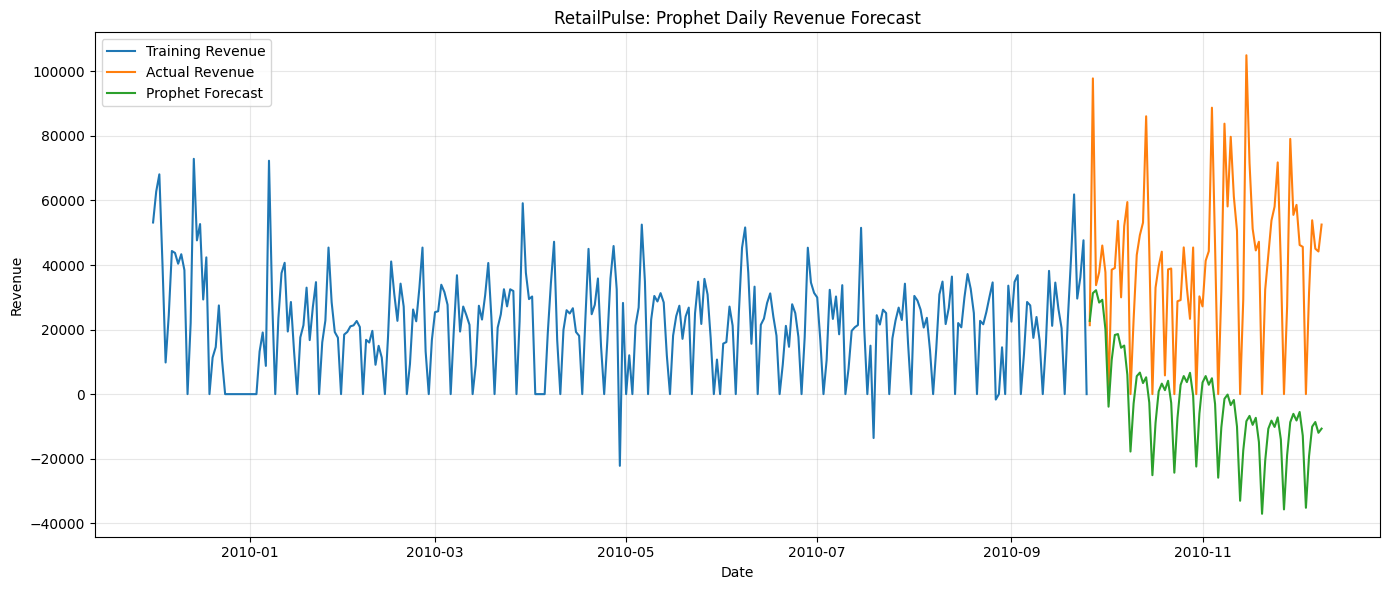

In [ ]:
# Visualize actual vs. predicted revenue

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    train_df["ds"], train_df["y"],
    label="Training Revenue"
)

plt.plot(
    test_df["ds"], test_df["y"],
    label="Actual Revenue"
)

plt.plot(
    forecast["ds"], forecast["yhat"],
    label="Prophet Forecast"
)

plt.title("RetailPulse: Prophet Daily Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("Date range:", prophet_df["ds"].min(), "to", prophet_df["ds"].max())

print("\nRevenue statistics:")
display(prophet_df["y"].describe())

print("\nNegative revenue days:", (prophet_df["y"] < 0).sum())
print("Zero revenue days:", (prophet_df["y"] == 0).sum())
print("Missing revenue values:", prophet_df["y"].isna().sum())

Date range: 2009-12-01 00:00:00 to 2010-12-09 00:00:00

Revenue statistics:


,y
count,374.000000
mean,25506.643406
std,18956.312318
min,-22212.609000
25%,14688.365000
50%,24593.555000
75%,34821.202500
max,104983.550000



Negative revenue days: 3
Zero revenue days: 67
Missing revenue values: 0


Improved Prophet MAE: 21130.79
Improved Prophet RMSE: 27118.57


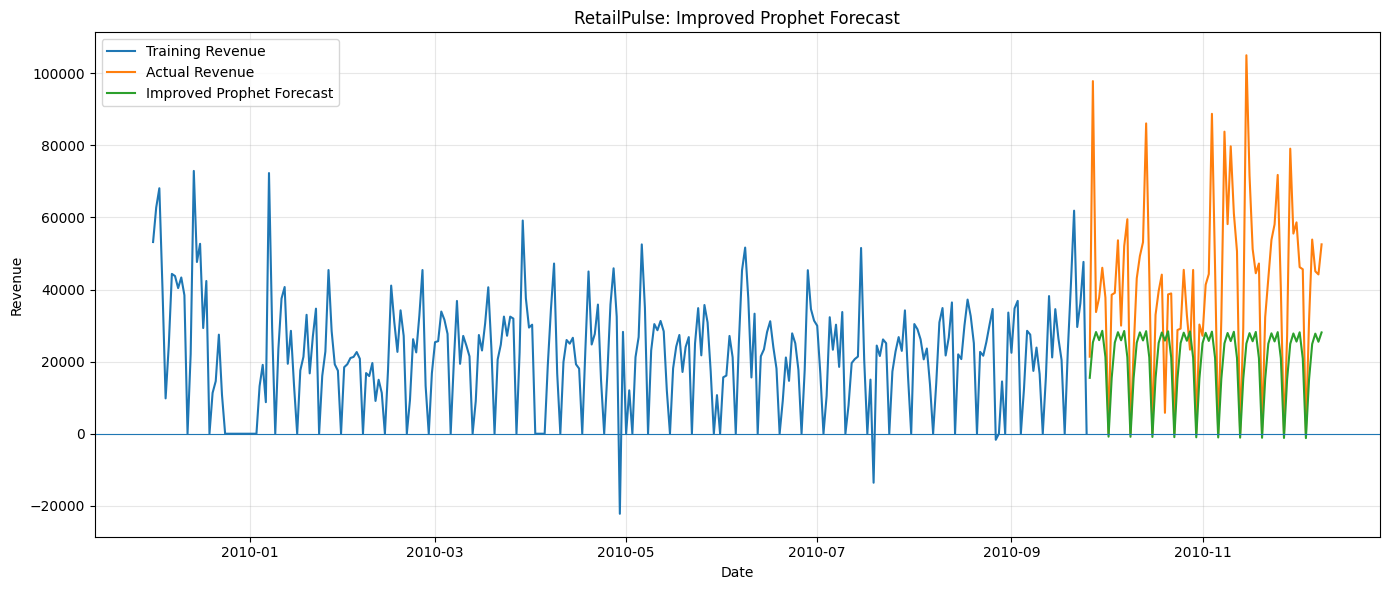

In [ ]:
# Tring an improved baseline model
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Keep the chronological train-test split
split_index = int(len(prophet_df) * 0.8)

train_df = prophet_df.iloc[:split_index].copy()
test_df = prophet_df.iloc[split_index:].copy()

# Build a less flexible model
model_improved = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.01,
    seasonality_prior_scale=1.0
)

model_improved.fit(train_df)

# Predict over the test period
forecast_improved = model_improved.predict(test_df[["ds"]])

# Evaluate
actual = test_df["y"].to_numpy()
predicted = forecast_improved["yhat"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Improved Prophet MAE:", round(mae, 2))
print("Improved Prophet RMSE:", round(rmse, 2))

# Plot
plt.figure(figsize=(14, 6))
plt.plot(train_df["ds"], train_df["y"], label="Training Revenue")
plt.plot(test_df["ds"], test_df["y"], label="Actual Revenue")
plt.plot(
    forecast_improved["ds"],
    forecast_improved["yhat"],
    label="Improved Prophet Forecast"
)
plt.axhline(0, linewidth=0.8)
plt.title("RetailPulse: Improved Prophet Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Forecast weekly revenue

weekly_revenue = (
    prophet_df
    .set_index("ds")["y"]
    .resample("W-SUN")
    .sum()
    .reset_index()
)

weekly_revenue.columns = ["ds", "y"]

display(weekly_revenue.head())
print("Weekly records:", len(weekly_revenue))

,ds,y
0,2009-12-06,258496.32
1,2009-12-13,232310.10
2,2009-12-20,256240.20
3,2009-12-27,52800.49
4,2010-01-03,0.00


Weekly records: 54


In [ ]:
# Split the data and train Prophet

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

split_index = int(len(weekly_revenue) * 0.8)

train_weekly = weekly_revenue.iloc[:split_index].copy()
test_weekly = weekly_revenue.iloc[split_index:].copy()

weekly_model = Prophet(
    weekly_seasonality=False,
    yearly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.05
)

weekly_model.fit(train_weekly)

weekly_forecast = weekly_model.predict(test_weekly[["ds"]])

actual = test_weekly["y"].to_numpy()
predicted = weekly_forecast["yhat"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Weekly Prophet MAE:", round(mae, 2))
print("Weekly Prophet RMSE:", round(rmse, 2))

Weekly Prophet MAE: 130168.23
Weekly Prophet RMSE: 141745.28


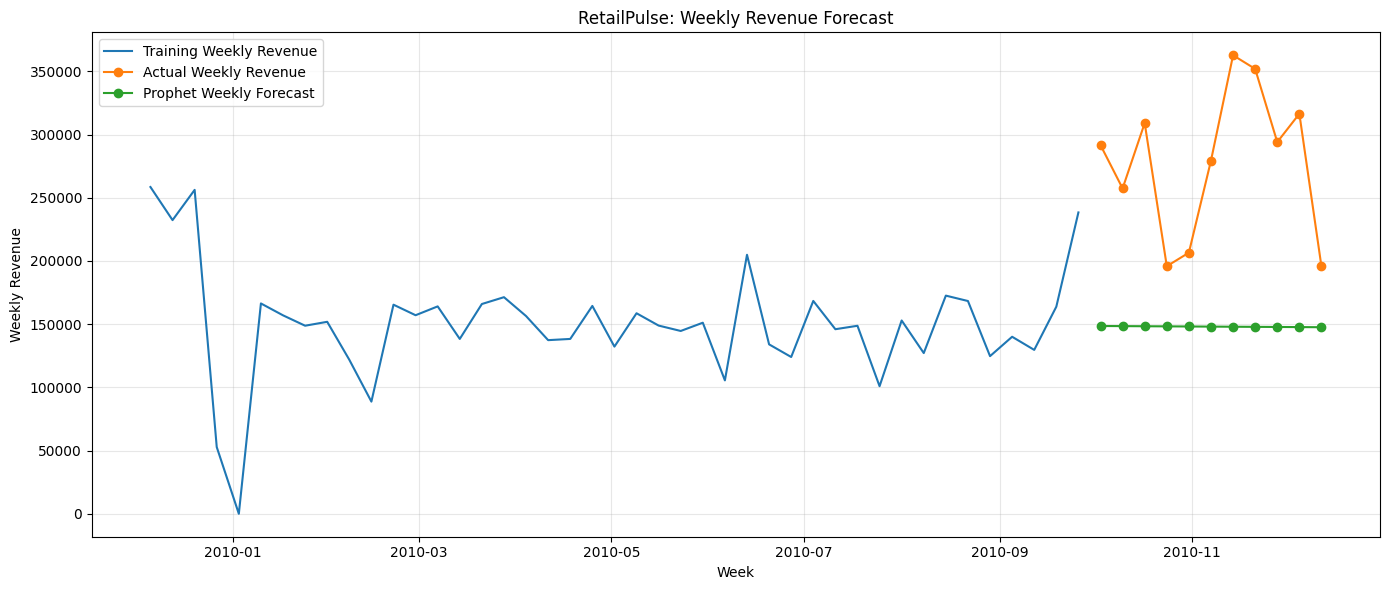

In [ ]:
# Plot weekly actual vs. forecast

plt.figure(figsize=(14, 6))

plt.plot(
    train_weekly["ds"], train_weekly["y"],
    label="Training Weekly Revenue"
)
plt.plot(
    test_weekly["ds"], test_weekly["y"],
    marker="o", label="Actual Weekly Revenue"
)
plt.plot(
    weekly_forecast["ds"], weekly_forecast["yhat"],
    marker="o", label="Prophet Weekly Forecast"
)

plt.title("RetailPulse: Weekly Revenue Forecast")
plt.xlabel("Week")
plt.ylabel("Weekly Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Weekly revenue

In [ ]:
#Aggregate daily revenue into weekly revenue

weekly_revenue = (
    prophet_df
    .set_index("ds")["y"]
    .resample("W-SUN")
    .sum()
    .reset_index()
)

weekly_revenue.columns = ["ds", "y"]

display(weekly_revenue.head())
print("Weekly records:", len(weekly_revenue))

,ds,y
0,2009-12-06,258496.32
1,2009-12-13,232310.10
2,2009-12-20,256240.20
3,2009-12-27,52800.49
4,2010-01-03,0.00


Weekly records: 54


In [ ]:
# Split into training and testing data
split_index = int(len(weekly_revenue) * 0.8)

train_weekly = weekly_revenue.iloc[:split_index].copy()
test_weekly = weekly_revenue.iloc[split_index:].copy()

print("Training weeks:", len(train_weekly))
print("Testing weeks:", len(test_weekly))

Training weeks: 43
Testing weeks: 11


In [ ]:
# Train the weekly Prophet model

weekly_model = Prophet(
    weekly_seasonality=False,
    yearly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.05
)

weekly_model.fit(train_weekly)

weekly_forecast = weekly_model.predict(test_weekly[["ds"]])

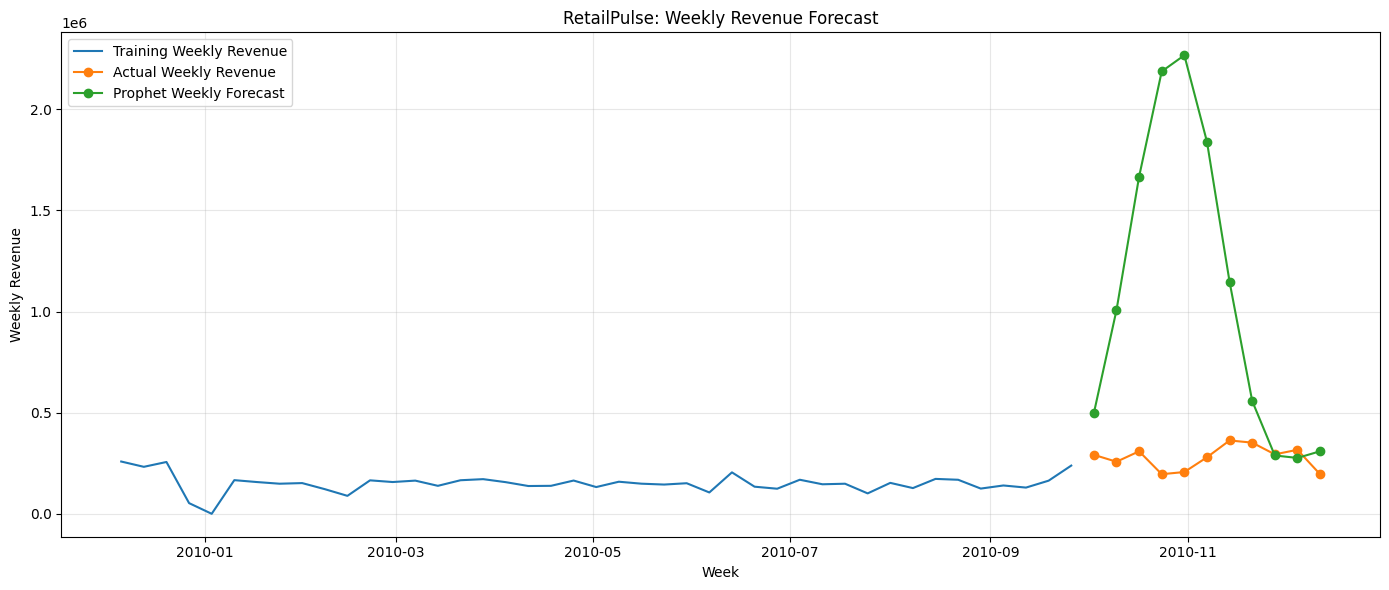

In [ ]:
# Plot the weekly forecast

plt.figure(figsize=(14, 6))

plt.plot(
    train_weekly["ds"], train_weekly["y"],
    label="Training Weekly Revenue"
)
plt.plot(
    test_weekly["ds"], test_weekly["y"],
    marker="o", label="Actual Weekly Revenue"
)
plt.plot(
    weekly_forecast["ds"], weekly_forecast["yhat"],
    marker="o", label="Prophet Weekly Forecast"
)

plt.title("RetailPulse: Weekly Revenue Forecast")
plt.xlabel("Week")
plt.ylabel("Weekly Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Evaluate the weekly model

from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_weekly["y"].to_numpy()
predicted = weekly_forecast["yhat"].to_numpy()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Weekly Prophet MAE:", round(mae, 2))
print("Weekly Prophet RMSE:", round(rmse, 2))

Weekly Prophet MAE: 825216.72
Weekly Prophet RMSE: 1118969.55


In [ ]:
# Compare Prophet with simple baseline models

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_weekly["y"].to_numpy()
prophet_pred = weekly_forecast["yhat"].to_numpy()

# Baseline 1: Mean weekly revenue from training data
mean_pred = np.full(
    len(test_weekly),
    train_weekly["y"].mean()
)

# Baseline 2: Previous week's actual revenue
naive_pred = (
    weekly_revenue["y"]
    .shift(1)
    .loc[test_weekly.index]
    .to_numpy()
)

def calculate_metrics(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

comparison = pd.DataFrame([
    calculate_metrics("Training Mean Baseline", actual, mean_pred),
    calculate_metrics("Naive Baseline", actual, naive_pred),
    calculate_metrics("Weekly Prophet", actual, prophet_pred)
])

comparison[["MAE", "RMSE"]] = comparison[["MAE", "RMSE"]].round(2)

display(comparison.sort_values("MAE"))

,Model,MAE,RMSE
1,Naive Baseline,57384.47,67710.81
0,Training Mean Baseline,127572.63,139353.83
2,Weekly Prophet,825216.72,1118969.55


In [ ]:
# Check the scale of weekly revenue

print("Average actual weekly revenue:", round(test_weekly["y"].mean(), 2))
print("Median actual weekly revenue:", round(test_weekly["y"].median(), 2))
print("Minimum actual weekly revenue:", round(test_weekly["y"].min(), 2))
print("Maximum actual weekly revenue:", round(test_weekly["y"].max(), 2))

Average actual weekly revenue: 278242.74
Median actual weekly revenue: 291652.13
Minimum actual weekly revenue: 195641.2
Maximum actual weekly revenue: 362717.61


In [ ]:
# Important check: forecast dates and revenue alignment

print("Actual test dates:")
display(test_weekly[["ds", "y"]].head(10))

print("Prophet forecast dates:")
display(weekly_forecast[["ds", "yhat"]].head(10))

print("Test date range:",
      test_weekly["ds"].min(),
      "to",
      test_weekly["ds"].max())

print("Forecast date range:",
      weekly_forecast["ds"].min(),
      "to",
      weekly_forecast["ds"].max())

print("Same dates:",
      test_weekly["ds"].reset_index(drop=True).equals(
          weekly_forecast["ds"].reset_index(drop=True)
      ))

Actual test dates:


,ds,y
43,2010-10-03,291652.130
44,2010-10-10,257386.970
45,2010-10-17,309080.930
46,2010-10-24,195850.020
47,2010-10-31,206556.980
48,2010-11-07,279382.870
49,2010-11-14,362717.611
50,2010-11-21,351931.091
51,2010-11-28,294028.020
52,2010-12-05,316442.300


Prophet forecast dates:


,ds,yhat
0,2010-10-03,4.977274e+05
1,2010-10-10,1.006933e+06
2,2010-10-17,1.667318e+06
3,2010-10-24,2.187773e+06
4,2010-10-31,2.267673e+06
5,2010-11-07,1.840069e+06
6,2010-11-14,1.147090e+06
7,2010-11-21,5.579633e+05
8,2010-11-28,2.883525e+05
9,2010-12-05,2.762786e+05


Test date range: 2010-10-03 00:00:00 to 2010-12-12 00:00:00
Forecast date range: 2010-10-03 00:00:00 to 2010-12-12 00:00:00
Same dates: True


In [ ]:
# Verify the Naive Baseline calculation

weekly_revenue = weekly_revenue.sort_values("ds").reset_index(drop=True)

split_index = int(len(weekly_revenue) * 0.8)

train_weekly = weekly_revenue.iloc[:split_index].copy()
test_weekly = weekly_revenue.iloc[split_index:].copy()

# Previous week's actual revenue
naive_pred = weekly_revenue["y"].shift(1).iloc[split_index:].to_numpy()

actual = test_weekly["y"].to_numpy()

print("Naive MAE:",
      round(mean_absolute_error(actual, naive_pred), 2))

print("Naive RMSE:",
      round(np.sqrt(mean_squared_error(actual, naive_pred)), 2))

Naive MAE: 57384.47
Naive RMSE: 67710.81


In [ ]:
# Validate the Prophet forecast dates

print("Actual test dates:")
display(test_weekly[["ds", "y"]].head())

print("Prophet forecast dates:")
display(weekly_forecast[["ds", "yhat"]].head())

dates_match = (
    test_weekly["ds"].reset_index(drop=True).equals(
        weekly_forecast["ds"].reset_index(drop=True)
    )
)

print("Dates match:", dates_match)

Actual test dates:


,ds,y
43,2010-10-03,291652.13
44,2010-10-10,257386.97
45,2010-10-17,309080.93
46,2010-10-24,195850.02
47,2010-10-31,206556.98


Prophet forecast dates:


,ds,yhat
0,2010-10-03,4.977274e+05
1,2010-10-10,1.006933e+06
2,2010-10-17,1.667318e+06
3,2010-10-24,2.187773e+06
4,2010-10-31,2.267673e+06


Dates match: True


In [ ]:
# Investigate the unusually large predictions

# Check the training and test revenue ranges
print("Training revenue statistics:")
display(train_weekly["y"].describe())

print("\nActual test revenue statistics:")
display(test_weekly["y"].describe())

print("\nProphet forecast statistics:")
display(weekly_forecast["yhat"].describe())

Training revenue statistics:


,y
count,43.00000
mean,150670.10493
std,45811.01177
min,0.00000
25%,133141.01050
50%,151146.90000
75%,165681.67650
max,258496.32000



Actual test revenue statistics:


,y
count,11.000000
mean,278242.738364
std,58814.836564
min,195641.200000
25%,231971.975000
50%,291652.130000
75%,312761.615000
max,362717.611000



Prophet forecast statistics:


,yhat
count,1.100000e+01
mean,1.095125e+06
std,7.775649e+05
min,2.762786e+05
25%,4.034626e+05
50%,1.006933e+06
75%,1.753693e+06
max,2.267673e+06


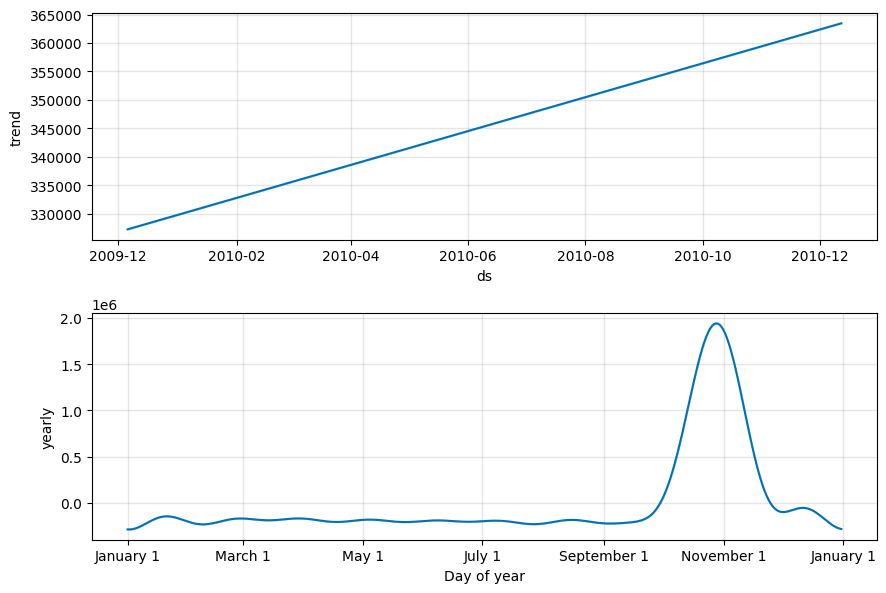

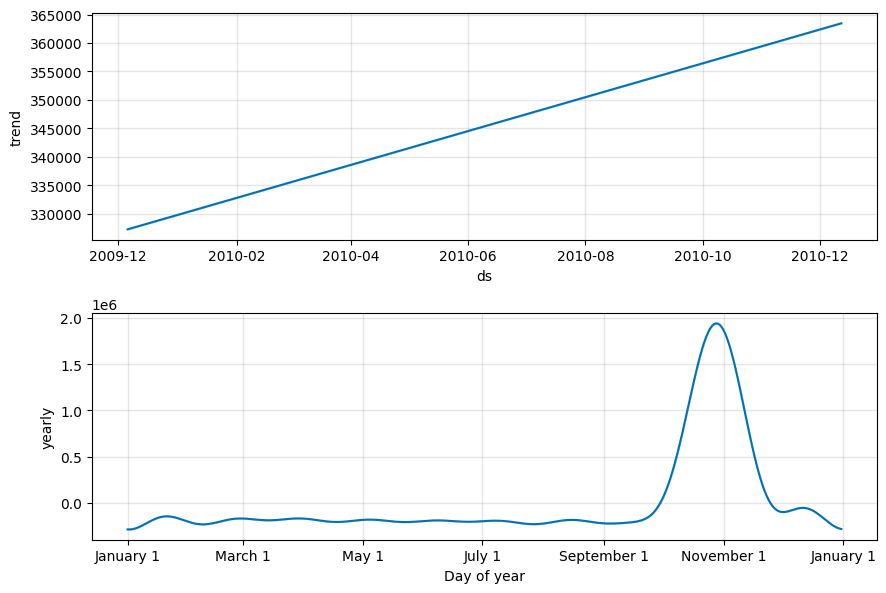

In [ ]:
# Check the Prophet forecast trend
weekly_model.plot_components(
    weekly_model.predict(weekly_revenue[["ds"]])
)

In [ ]:
# Compare actual and predicted values directly

forecast_comparison = test_weekly[["ds", "y"]].merge(
    weekly_forecast[["ds", "yhat"]],
    on="ds",
    how="inner"
)

forecast_comparison["Error"] = (
    forecast_comparison["y"] - forecast_comparison["yhat"]
)

forecast_comparison["Absolute_Error"] = (
    forecast_comparison["Error"].abs()
)

display(forecast_comparison.head(15))

,ds,y,yhat,Error,Absolute_Error
0,2010-10-03,291652.130,4.977274e+05,-2.060752e+05,2.060752e+05
1,2010-10-10,257386.970,1.006933e+06,-7.495460e+05,7.495460e+05
2,2010-10-17,309080.930,1.667318e+06,-1.358237e+06,1.358237e+06
3,2010-10-24,195850.020,2.187773e+06,-1.991923e+06,1.991923e+06
4,2010-10-31,206556.980,2.267673e+06,-2.061117e+06,2.061117e+06
5,2010-11-07,279382.870,1.840069e+06,-1.560686e+06,1.560686e+06
6,2010-11-14,362717.611,1.147090e+06,-7.843725e+05,7.843725e+05
7,2010-11-21,351931.091,5.579633e+05,-2.060322e+05,2.060322e+05
8,2010-11-28,294028.020,2.883525e+05,5.675492e+03,5.675492e+03
9,2010-12-05,316442.300,2.762786e+05,4.016371e+04,4.016371e+04


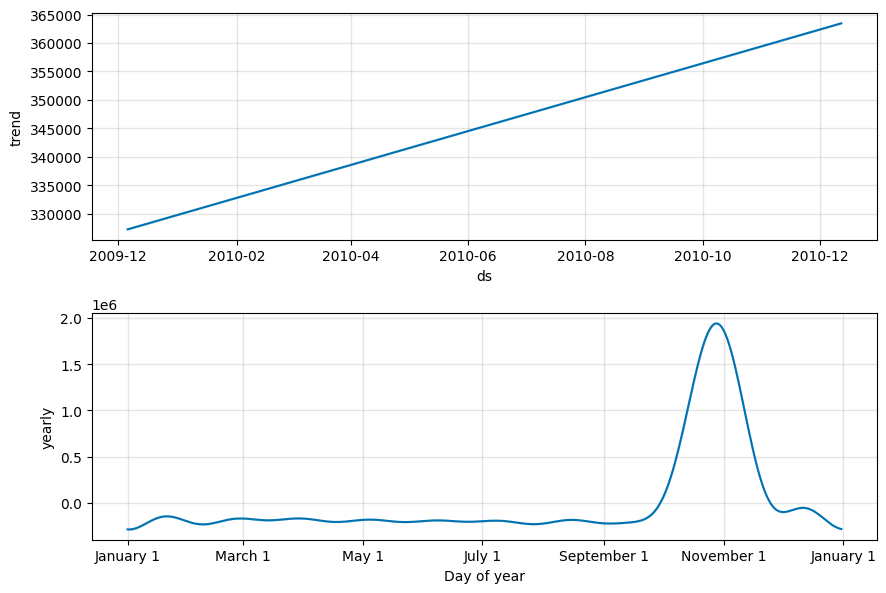

In [ ]:
# inspect Prophet's components

# Generate predictions for the full weekly dataset
full_weekly_forecast = weekly_model.predict(
    weekly_revenue[["ds"]]
)

# Plot trend and seasonal components
weekly_model.plot_components(full_weekly_forecast)
plt.show()

In [ ]:
display(
    full_weekly_forecast[
        ["ds", "trend", "yearly", "yhat"]
    ].tail(20)
)

,ds,trend,yearly,yhat
34,2010-08-01,350477.545442,-2.247613e+05,1.257162e+05
35,2010-08-08,351160.790419,-2.007691e+05,1.503916e+05
36,2010-08-15,351844.035396,-1.846579e+05,1.671861e+05
37,2010-08-22,352527.280373,-1.944605e+05,1.580668e+05
38,2010-08-29,353210.525351,-2.156647e+05,1.375458e+05
39,2010-09-05,353893.770328,-2.236505e+05,1.302433e+05
40,2010-09-12,354577.015305,-2.163694e+05,1.382077e+05
41,2010-09-19,355260.260282,-1.971248e+05,1.581355e+05
42,2010-09-26,355943.505259,-1.158216e+05,2.401219e+05
43,2010-10-03,356626.750237,1.411006e+05,4.977274e+05


In [ ]:
# flexible trend

weekly_model_v2 = Prophet(
    weekly_seasonality=False,
    yearly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.001
)

weekly_model_v2.fit(train_weekly)

weekly_forecast_v2 = weekly_model_v2.predict(
    test_weekly[["ds"]]
)

actual = test_weekly["y"].to_numpy()
predicted_v2 = weekly_forecast_v2["yhat"].to_numpy()

print("Prophet v2 MAE:",
      round(mean_absolute_error(actual, predicted_v2), 2))

print("Prophet v2 RMSE:",
      round(np.sqrt(mean_squared_error(actual, predicted_v2)), 2))

Prophet v2 MAE: 137626.99
Prophet v2 RMSE: 148631.11


In [ ]:
# Comparison table

comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Training Mean Baseline",
        "Prophet v1",
        "Prophet v2"
    ],
    "MAE": [
        57384.47,
        127572.63,
        825216.72,
        137626.99
    ],
    "RMSE": [
        67710.81,
        139353.83,
        1118969.55,
        148631.11
    ]
})

display(comparison.sort_values("MAE").reset_index(drop=True))

,Model,MAE,RMSE
0,Naive Baseline,57384.47,67710.81
1,Training Mean Baseline,127572.63,139353.83
2,Prophet v2,137626.99,148631.11
3,Prophet v1,825216.72,1118969.55


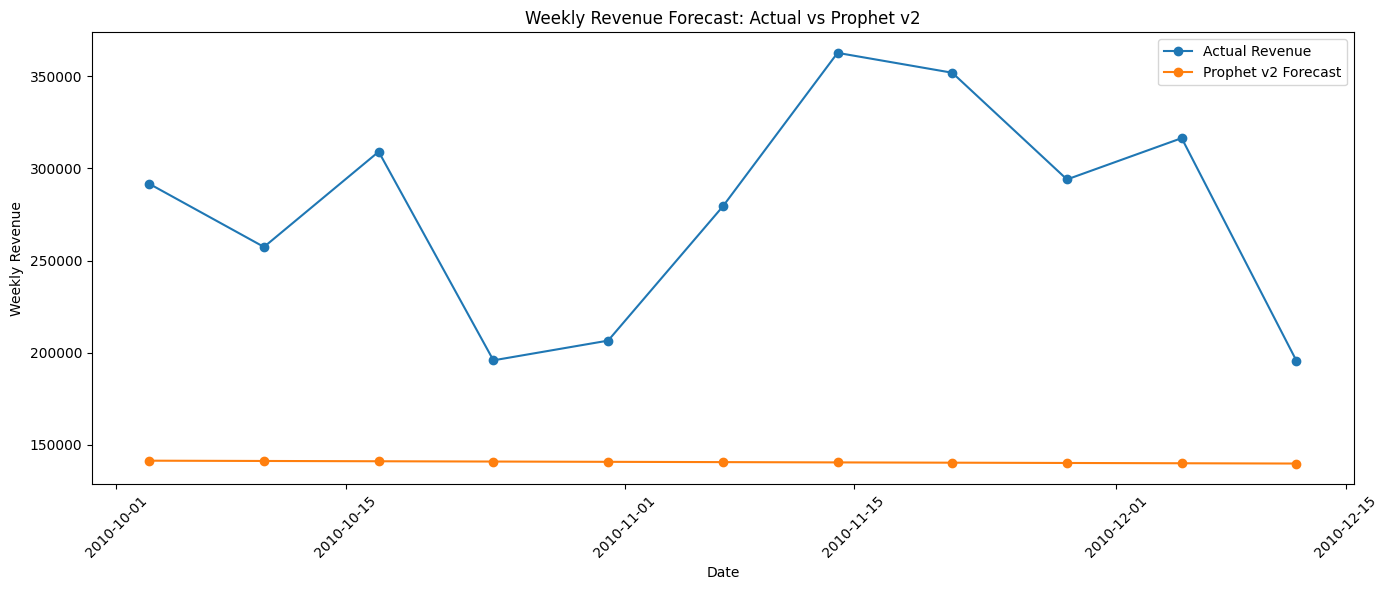

In [ ]:
# Plot the Prophet v2 predictions against actual revenue

plt.figure(figsize=(14, 6))

plt.plot(
    test_weekly["ds"],
    test_weekly["y"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    weekly_forecast_v2["ds"],
    weekly_forecast_v2["yhat"],
    marker="o",
    label="Prophet v2 Forecast"
)

plt.title("Weekly Revenue Forecast: Actual vs Prophet v2")
plt.xlabel("Date")
plt.ylabel("Weekly Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key insights

The weekly revenue forecasting task was completed using Prophet. Two Prophet configurations were evaluated alongside a naive baseline and a training-mean baseline.

Prophet v2 reduced the extreme forecast errors observed in v1, but the naive baseline achieved the best results on the test dataset. Therefore, the naive baseline is the current best-performing approach for this evaluation, while Prophet v2 remains a useful experimental model.

The results demonstrate the importance of comparing complex forecasting models against simple benchmarks rather than assuming that a more advanced model will always perform better.